# 01 — Exploration et préparation des données (Phase 2)

Répartition par hôpital/lame/patiente/classe, grille d'exemples 5 hôpitaux × 2 classes, histogrammes RGB/HSV par hôpital, contrôle qualité, assert anti-fuite, Dataset PyTorch.

Voir `PLAN.md` pour le détail de la phase correspondante.

In [1]:
# Colab/Kaggle : clone le depot si besoin et place le repertoire de travail dans notebooks/
# (sans effet en local : le depot est deja la, donc rien n'est clone ni deplace)
import os, subprocess, sys

REPO_URL = "https://github.com/YoucefLgr/Breast_Cancer.git"
EN_COLAB = "COLAB_GPU" in os.environ or "COLAB_RELEASE_TAG" in os.environ
EN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ or os.path.exists("/kaggle/input")

if EN_COLAB or EN_KAGGLE:
    repo_dir = "/content/Breast_Cancer" if EN_COLAB else "/kaggle/working/Breast_Cancer"
    if not os.path.isdir(repo_dir):
        subprocess.run(["git", "clone", REPO_URL, repo_dir], check=True)
    os.chdir(os.path.join(repo_dir, "notebooks"))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "../requirements.txt"], check=True)

print("Repertoire de travail :", os.getcwd())

Repertoire de travail : C:\Users\Youcef Lagraa\OneDrive\Bureau\Breast Cancer\Breast_Cancer\notebooks


In [2]:
# Setup — à exécuter en premier dans chaque notebook
import sys, os
sys.path.insert(0, os.path.abspath(".."))  # pour pouvoir faire `from src...` depuis notebooks/

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

from src.utils import load_config, set_seed, get_device, detect_environment, get_path

CFG = load_config()
set_seed(CFG["seed"])
print("Environnement :", detect_environment())
print("Device :", get_device())

Environnement : local
ATTENTION : aucun GPU détecté, calcul sur CPU. Un entraînement CNN complet doit se faire sur Colab/Kaggle (GPU gratuit).
Device : cpu


## 1. Répartition des patchs : hôpital, lame, patiente, classe

Sur les **métadonnées complètes** (455 954 patchs, 50 lames annotées) puis sur le **sous-échantillon** (39 000 patchs, équilibré par construction).

In [3]:
from src.data import charger_metadonnees, charger_stages, construire_table_lames, verifier_absence_fuite

meta = charger_metadonnees(CFG)
print(f"{len(meta):,} patchs, {meta.slide.nunique()} lames, {meta.patient.nunique()} patientes")

print("\n-- métadonnées complètes : split x hôpital --")
display(pd.crosstab(meta.split, meta.center))
print("\n-- métadonnées complètes : split x label --")
display(pd.crosstab(meta.split, meta.label))
print("\n-- lames par hôpital --", meta.groupby("center").slide.nunique().to_dict())
print("-- patientes par hôpital --", meta.groupby("center").patient.nunique().to_dict())

455,954 patchs, 50 lames, 43 patientes

-- métadonnées complètes : split x hôpital --


center,0,1,2,3,4
split,,,,,
id_val,6011,0,0,12879,14670
test,0,0,85054,0,0
train,53425,0,0,116959,132052
val_ood,0,34904,0,0,0



-- métadonnées complètes : split x label --


label,0,1
split,,
id_val,16952,16608
test,42527,42527
train,151046,151390
val_ood,17452,17452



-- lames par hôpital -- {0: 10, 1: 10, 2: 10, 3: 10, 4: 10}
-- patientes par hôpital -- {0: 7, 1: 8, 2: 9, 3: 10, 4: 9}


In [4]:
ids = pd.read_csv(get_path(CFG, "ids_csv"))
sous_ech = meta.merge(ids.drop(columns=["split"]), on="image_id", how="inner")
assert len(sous_ech) == len(ids), "jointure incomplète entre ids_sous_echantillon.csv et les métadonnées"
print(f"{len(sous_ech):,} patchs dans le sous-échantillon (sur {len(ids):,} id attendus)")

print("\n-- sous-échantillon : split x hôpital --")
display(pd.crosstab(sous_ech.split, sous_ech.center))
print("\n-- sous-échantillon : hôpital x classe (équilibré par construction) --")
display(pd.crosstab(sous_ech.center, sous_ech.label))

39,000 patchs dans le sous-échantillon (sur 39,000 id attendus)

-- sous-échantillon : split x hôpital --


center,0,1,2,3,4
split,,,,,
id_val,1000,0,0,1000,1000
test,0,0,8000,0,0
train,8000,0,0,8000,8000
val_ood,0,4000,0,0,0



-- sous-échantillon : hôpital x classe (équilibré par construction) --


label,0,1
center,,
0,4500,4500
1,2000,2000
2,4000,4000
3,4500,4500
4,4500,4500


In [5]:
lames = construire_table_lames(meta, CFG)
print("Classes officielles des 50 lames annotées :", lames.classe_officielle.value_counts().to_dict())
print("\nPart tumorale (sur les métadonnées complètes de chaque lame) par classe officielle :")
display(lames.groupby("classe_officielle").part_tumorale.describe()[["count", "min", "50%", "max"]].round(4))
print("\nNombre de patchs par lame : min =", lames.n_patchs.min(), ", max =", lames.n_patchs.max())
print("Nombre de lames annotées par patiente :", lames.groupby("patient").size().value_counts().to_dict())

Classes officielles des 50 lames annotées : {'micro': 17, 'macro': 17, 'itc': 16}

Part tumorale (sur les métadonnées complètes de chaque lame) par classe officielle :


,count,min,50%,max
classe_officielle,,,,
itc,16.0,0.0010,0.0046,0.0360
macro,17.0,0.2466,0.6469,0.9276
micro,17.0,0.0124,0.0668,0.2946



Nombre de patchs par lame : min = 888 , max = 61110
Nombre de lames annotées par patiente : {1: 37, 2: 5, 3: 1}


**Constat 1** : même restreint aux 50 lames qui contiennent toutes au moins une cellule tumorale, la part de tissu tumoral par lame varie de moins de 0,1 % (cellules isolées) à plus de 90 % (grosses macro-métastases) — la difficulté de détection n'est pas la même selon la classe de lame.

## 2. Garde-fou anti-fuite

`id_val` partage ses lames avec `train` par construction officielle de WILDS (mêmes hôpitaux 0/3/4) : documenté, ce n'est pas une fuite. `verifier_absence_fuite` regroupe `train` + `id_val` puis vérifie qu'aucune `slide` ni `patient` n'apparaît dans deux groupes réellement distincts (groupe train union id_val / hôpital 1 / hôpital 2).

In [6]:
verifier_absence_fuite(meta)
verifier_absence_fuite(sous_ech)
verifier_absence_fuite(lames)
print("Aucune fuite détectée sur les métadonnées complètes, le sous-échantillon et la table des lames.")

Aucune fuite détectée sur les métadonnées complètes, le sous-échantillon et la table des lames.


## 3. Grille d'exemples : 5 hôpitaux × 2 classes

Nécessite les images du sous-échantillon (parquet reconstruit depuis Hugging Face, voir README). Si le fichier n'existe pas encore, `charger_sous_echantillon` le télécharge automatiquement (~10 Go, 10-20 min, mis en cache ensuite).

In [7]:
from src.data import charger_sous_echantillon, ouvrir, HOPITAL_LABEL

df_img = charger_sous_echantillon(CFG)
print(f"{len(df_img):,} patchs avec image chargés")

39,000 patchs avec image chargés


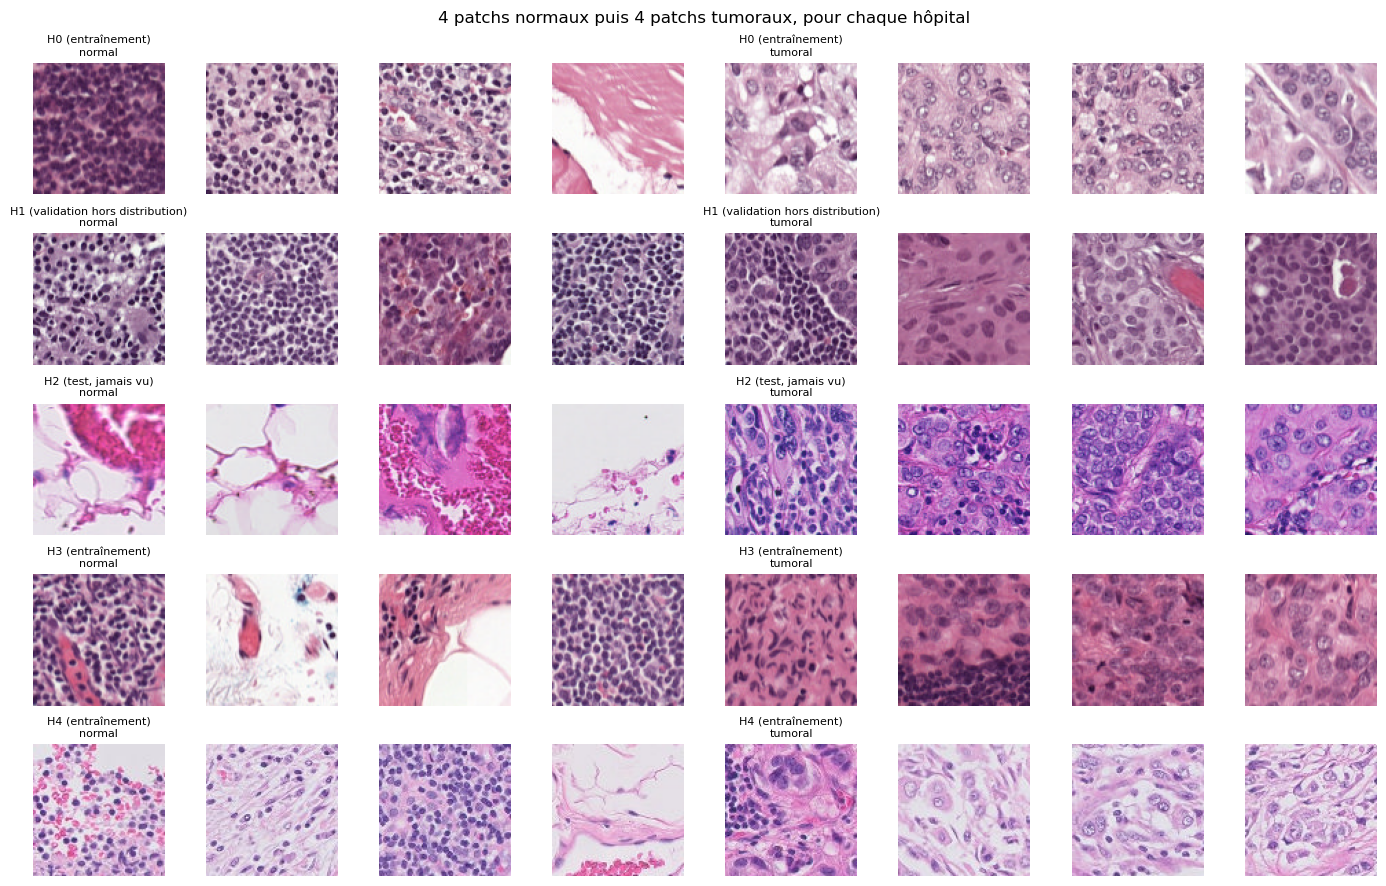

In [8]:
fig, axes = plt.subplots(5, 8, figsize=(14, 9))
for r, h in enumerate(range(5)):
    for c in range(8):
        lab = c // 4
        sous = df_img[(df_img.center == h) & (df_img.label == lab)]
        if len(sous) == 0:
            axes[r, c].axis("off")
            continue
        s = sous.sample(1, random_state=CFG["seed"] + c)
        axes[r, c].imshow(ouvrir(s.image.iloc[0]))
        axes[r, c].axis("off")
        if c in (0, 4):
            titre_classe = "tumoral" if lab else "normal"
            axes[r, c].set_title(f"{HOPITAL_LABEL[h]}\n{titre_classe}", fontsize=8)
plt.suptitle("4 patchs normaux puis 4 patchs tumoraux, pour chaque hôpital")
plt.tight_layout()
plt.savefig("../outputs/figures/01_grille_exemples.png", dpi=130)
plt.show()

## 4. Histogrammes RGB et HSV moyens par hôpital

Quantifie le shift de couleur entre hôpitaux : si les distributions se recouvrent peu, un modèle risque d'apprendre la teinte de l'hôpital plutôt que la morphologie cellulaire.

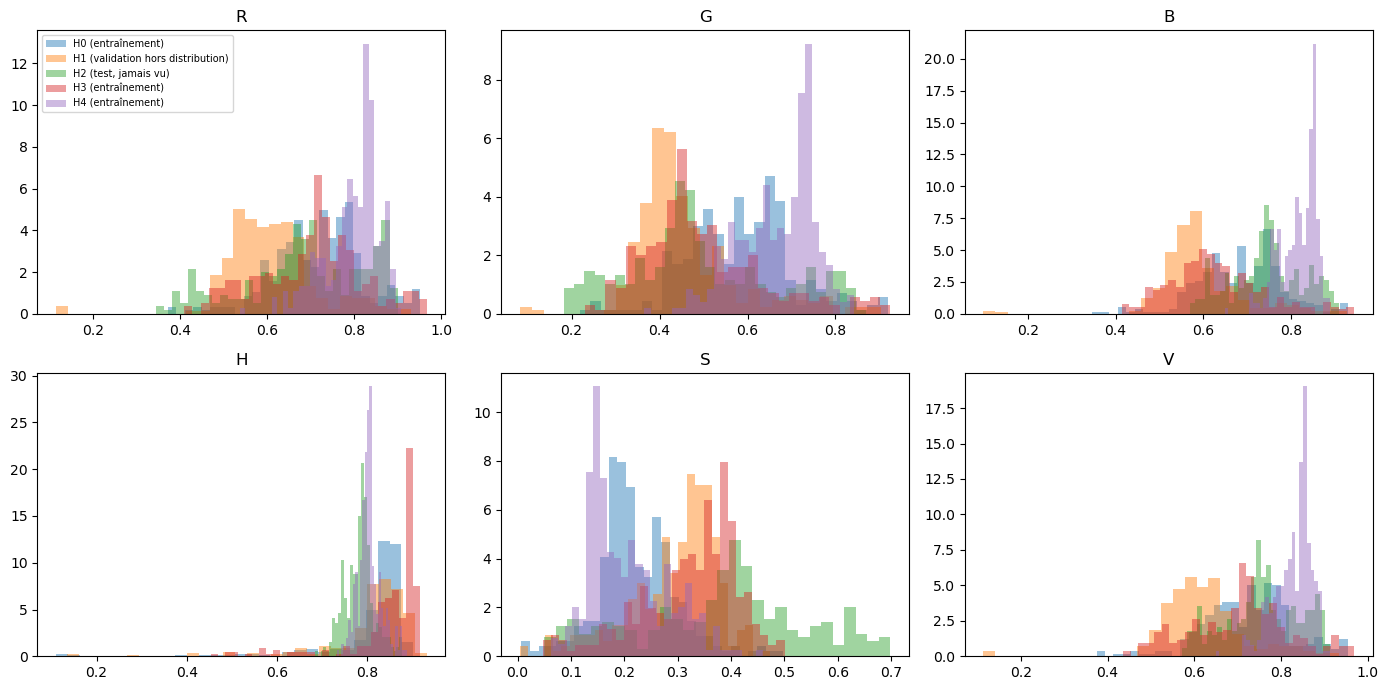

Moyenne par hôpital (R, G, B, H, S, V) :


,R,G,B,H,S,V
center,,,,,,
0,0.718,0.584,0.685,0.810,0.222,0.725
1,0.609,0.459,0.591,0.805,0.295,0.620
2,0.684,0.497,0.746,0.782,0.379,0.760
3,0.700,0.499,0.630,0.846,0.323,0.706
4,0.798,0.667,0.818,0.805,0.206,0.829


In [9]:
import matplotlib.colors as mcolors

def stats_couleur(b):
    a = np.asarray(ouvrir(b), dtype=np.float32) / 255.0
    rgb_moy = a.reshape(-1, 3).mean(0)
    hsv = mcolors.rgb_to_hsv(a).reshape(-1, 3)
    return np.concatenate([rgb_moy, hsv.mean(0)])

ech = df_img.sample(frac=1, random_state=CFG["seed"]).groupby("center").head(300).copy()
stats = np.stack(ech.image.map(stats_couleur).values)
cols = ["R", "G", "B", "H", "S", "V"]
for k, v in enumerate(cols):
    ech[v] = stats[:, k]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for k, col in enumerate(cols):
    ax = axes[k // 3, k % 3]
    for h in range(5):
        ax.hist(ech.loc[ech.center == h, col], bins=30, alpha=.45, label=HOPITAL_LABEL[h], density=True)
    ax.set_title(col)
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.savefig("../outputs/figures/02_histogrammes_couleur.png", dpi=130)
plt.show()

print("Moyenne par hôpital (R, G, B, H, S, V) :")
display(ech.groupby("center")[cols].mean().round(3))

## 5. Contrôle qualité

Proportion de pixels très clairs (fond de lame / zones sans tissu) et flou (variance du Laplacien) par patch, par hôpital.

In [10]:
from scipy.ndimage import laplace

def qc_metrics(b):
    a = np.asarray(ouvrir(b).convert("L"), dtype=np.float32)
    part_claire = (a > 220).mean()
    nettete = laplace(a).var()
    return part_claire, nettete

ech_qc = df_img.sample(frac=1, random_state=CFG["seed"]).groupby("center").head(300).copy()
qc = np.stack(ech_qc.image.map(qc_metrics).values)
ech_qc["part_claire"] = qc[:, 0]
ech_qc["nettete"] = qc[:, 1]

display(ech_qc.groupby("center")[["part_claire", "nettete"]].describe().round(3))

seuil_blanc, seuil_flou = 0.9, ech_qc.nettete.quantile(0.02)
patchs_blancs = ech_qc[ech_qc.part_claire > seuil_blanc]
patchs_flous = ech_qc[ech_qc.nettete < seuil_flou]
print(f"Patchs quasi blancs (plus de {seuil_blanc:.0%} de pixels clairs) : {len(patchs_blancs)}/{len(ech_qc)}")
print(f"Patchs tres peu nets (percentile 2) : {len(patchs_flous)}/{len(ech_qc)}")

part_claire                                                  nettete  \
             count   mean    std    min    25%    50%    75%    max   count   
center                                                                        
0            300.0  0.139  0.174  0.000  0.028  0.070  0.174  0.865   300.0   
1            300.0  0.080  0.163  0.000  0.003  0.012  0.042  0.823   300.0   
2            300.0  0.155  0.235  0.000  0.005  0.023  0.204  0.853   300.0   
3            300.0  0.089  0.181  0.000  0.002  0.010  0.068  0.880   300.0   
4            300.0  0.169  0.158  0.001  0.028  0.153  0.246  0.770   300.0   

                                                                              
            mean       std      min       25%       50%       75%        max  
center                                                                        
0       2134.976  1365.026  139.404  1041.682  1929.473  2846.895   6717.035  
1       2544.848  1671.019    1.254  1135.448  2283.879  3651.155   7975.336  
2       2657.249  1196.342  265.063  1792.640  2690.557  3447.947   6656.281  
3       1339.811  1085.958  120.589   651.050   868.723  1702.704   6681.036  
4       3550.957  1927.551  391.121  2204.903  3114.876  4682.856  10904.129

Patchs quasi blancs (plus de 90% de pixels clairs) : 0/1500
Patchs tres peu nets (percentile 2) : 30/1500


## 6. Dataset PyTorch

Resize 96→224 (pour réutiliser un réseau pré-entraîné ImageNet en Phase 4), normalisation ImageNet, augmentations géométriques (flips, rotations de 90°) à l'entraînement uniquement.

In [11]:
import torch
from torch.utils.data import DataLoader
from src.data import PatchDataset, transform_entrainement, transform_evaluation

ds = PatchDataset(df_img[df_img.split == "train"].reset_index(drop=True), transform_entrainement(CFG))
x, y = ds[0]
print("tenseur :", x.shape, x.dtype, "label :", y)

dl = DataLoader(ds, batch_size=8, shuffle=True, generator=torch.Generator().manual_seed(CFG["seed"]))
xb, yb = next(iter(dl))
print("batch :", xb.shape, yb.shape)

tenseur : torch.Size([3, 96, 96]) torch.float32 label : 1
batch : torch.Size([8, 3, 96, 96]) torch.Size([8])


## 7. Constats et rapport

Voir `outputs/rapport/02_donnees.md` pour les 3 constats chiffrés, la justification de chaque prétraitement et la discussion équilibré/clinique.